In [8]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Atualizado para o formato CSV
caminho_arquivo = "/content/drive/MyDrive/Big Data/steam_2026_organizada.csv"

try:
    # Lendo o CSV diretamente com o Polars (muito mais rápido que o Excel)
    df = pl.read_csv(caminho_arquivo, ignore_errors=True)

    print("Arquivo carregado com sucesso!")
    print("Colunas disponíveis no arquivo:", df.columns)
    display(df.head())
except Exception as e:
    print(f"Erro ao tentar carregar o arquivo CSV: {e}")
    print("Verifique se o nome do arquivo e a pasta estão corretos no Google Drive.")

Arquivo carregado com sucesso!
Colunas disponíveis no arquivo: ['AppID', 'Nome do jogo', 'Lançamento', 'Gêneros', 'Desenvolvedores', 'Editoras', 'Preço', 'Desconto (%)', 'Quantidade de DLCs', 'Idade mínima', 'Proprietários estimados', 'Pico de jogadores simultâneos', 'Avaliações positivas', 'Avaliações negativas', 'Recomendações', 'Nota Metacritic', 'Nota dos usuários', 'Conquistas', 'Tempo médio total', 'Tempo médio em 2 semanas', 'Tempo mediano total', 'Tempo mediano em 2 semanas', 'Windows', 'Mac', 'Linux', 'Categorias', 'Tags']


AppID,Nome do jogo,Lançamento,Gêneros,Desenvolvedores,Editoras,Preço,Desconto (%),Quantidade de DLCs,Idade mínima,Proprietários estimados,Pico de jogadores simultâneos,Avaliações positivas,Avaliações negativas,Recomendações,Nota Metacritic,Nota dos usuários,Conquistas,Tempo médio total,Tempo médio em 2 semanas,Tempo mediano total,Tempo mediano em 2 semanas,Windows,Mac,Linux,Categorias,Tags
i64,str,str,str,str,str,f64,i64,i64,i64,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,str
496350,"""Supipara - Chapter 1 Spring Ha…","""2016-07-29 00:00:00""","""Adventure""","""minori""","""MangaGamer""",5.24,65,0,0,"""0 - 20000""",0,252,3,231,0,0,0,8,0,8,0,"""Sim""","""Não""","""Não""","""Single-player,Steam Trading Ca…","""Adventure,Visual Novel,Anime,C…"
1034400,"""Mystery Solitaire The Black Ra…","""2019-05-06 00:00:00""","""Casual""","""Somer Games""","""8floor""",4.99,0,0,0,"""0 - 20000""",0,21,3,0,0,0,0,0,0,0,0,"""Sim""","""Sim""","""Não""","""Single-player,Family Sharing""","""Casual,Card Game,Solitaire,Puz…"
3292190,"""버튜버 파라노이아 - Vtuber Paranoia""","""2024-10-31 00:00:00""","""Casual,Indie,Simulation""","""유진게임즈""","""유진게임즈""",8.99,0,1,0,"""0 - 20000""",1,0,0,0,0,0,19,0,0,0,0,"""Sim""","""Não""","""Não""","""Single-player,Steam Achievemen…",null
3631080,"""Maze Quest VR""","""2025-04-24 00:00:00""","""Action,Early Access""","""Reality Expanded LLC""","""Reality Expanded LLC""",4.99,0,0,0,"""0 - 20000""",0,0,0,0,0,0,0,0,0,0,0,"""Sim""","""Não""","""Não""","""Single-player,VR Only,Steam Le…",null
1654170,"""Agony VR""","""2023-04-05 00:00:00""","""Action,Adventure""","""Ignibit""","""Ignibit,Madmind Studio""",13.99,0,0,0,"""0 - 20000""",0,0,0,0,0,0,0,0,0,0,0,"""Sim""","""Não""","""Não""","""Single-player,Tracked Controll…",null


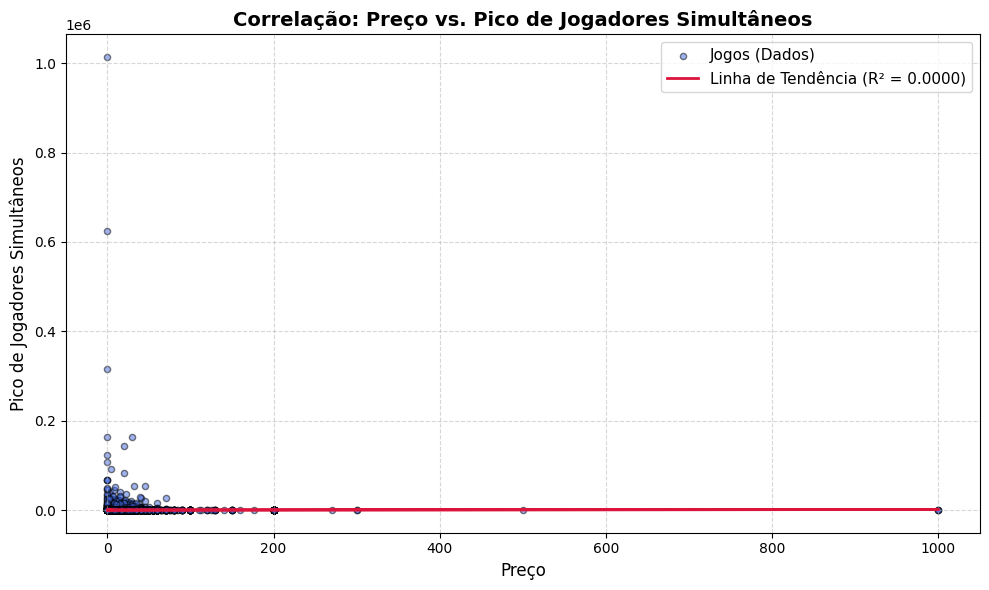

Coeficiente de Determinação (R²): 0.0000
Raiz do Erro Quadrático Médio (RMSE): 3859.66


In [10]:
# Removendo valores nulos para evitar erros no modelo
df_clean = df.select(["Preço", "Pico de jogadores simultâneos"]).drop_nulls()

# Preparando os dados para o Scikit-Learn
X = df_clean["Preço"].to_numpy().reshape(-1, 1)
y = df_clean["Pico de jogadores simultâneos"].to_numpy()

# Ajustando o modelo de regressão linear
model = LinearRegression()
model.fit(X, y)

# Prevendo os valores para traçar a linha de tendência
y_pred = model.predict(X)

# Calculando métricas de correlação e erro
r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

# Criando o gráfico de dispersão com a linha de regressão
plt.figure(figsize=(10, 6))
# Ajustei o tamanho dos pontos (s=20) e a transparência (alpha=0.5) para lidar com muitos dados
plt.scatter(df_clean["Preço"], df_clean["Pico de jogadores simultâneos"], color="royalblue", label="Jogos (Dados)", s=20, edgecolors="black", alpha=0.5)
plt.plot(df_clean["Preço"], y_pred, color="crimson", label=f"Linha de Tendência (R² = {r2:.4f})", linewidth=2)

# Customizações do gráfico
plt.title("Correlação: Preço vs. Pico de Jogadores Simultâneos", fontsize=14, fontweight="bold")
plt.xlabel("Preço", fontsize=12)
plt.ylabel("Pico de Jogadores Simultâneos", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()

# Exibindo o gráfico
plt.show()

print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Raiz do Erro Quadrático Médio (RMSE): {rmse:.2f}")